# Brain MRI dataset: exploratory analysis

Before training, check what the data looks like: how many images each class has, how image sizes vary, and what typical scans from each class look like. These checks decide the preprocessing in `brainmri/data.py`.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from brainmri import config

rows = []
for split, folder in [('train', config.TRAIN_DIR), ('test', config.TEST_DIR)]:
    for cls in config.CLASSES:
        for path in sorted((folder / cls).iterdir()):
            with Image.open(path) as img:
                rows.append(dict(split=split, cls=config.CLASS_LABELS[cls],
                                 path=path, width=img.width, height=img.height,
                                 mode=img.mode))
df = pd.DataFrame(rows)
df.head()

,split,cls,path,width,height,mode
0,train,Glioma,C:\Users\sachi\Projects\brain-mri-classifier\d...,512,512,L
1,train,Glioma,C:\Users\sachi\Projects\brain-mri-classifier\d...,512,512,L
2,train,Glioma,C:\Users\sachi\Projects\brain-mri-classifier\d...,512,512,L
3,train,Glioma,C:\Users\sachi\Projects\brain-mri-classifier\d...,512,512,L
4,train,Glioma,C:\Users\sachi\Projects\brain-mri-classifier\d...,512,512,L


## Class balance

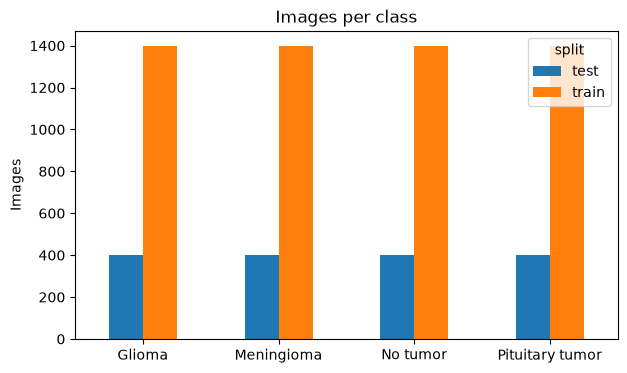

split,test,train
cls,,
Glioma,400,1400
Meningioma,400,1400
No tumor,400,1400
Pituitary tumor,400,1400


In [2]:
counts = df.pivot_table(index='cls', columns='split', values='path', aggfunc='count')
counts.plot.bar(figsize=(7, 4), rot=0, title='Images per class')
plt.ylabel('Images'); plt.xlabel(''); plt.show()
counts

The classes are balanced, so plain accuracy is a fair headline metric; macro F1 is reported alongside it anyway.

## Image sizes and colour modes

mode
RGB     4129
L       3067
RGBA       3
P          1
Name: count, dtype: int64

        width  height
count  7200.0  7200.0
mean    453.0   457.0
std     130.0   124.0
min     150.0   167.0
25%     442.0   449.0
50%     512.0   512.0
75%     512.0   512.0
max    1375.0  1446.0


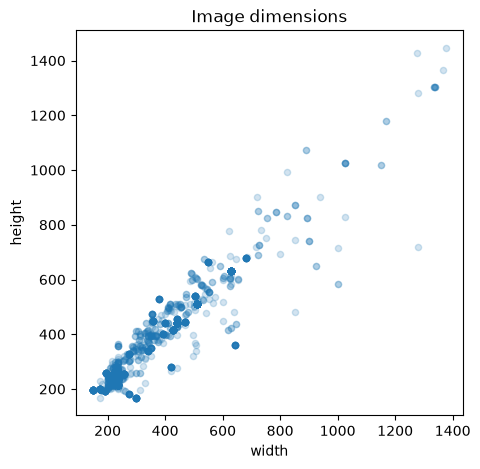

In [3]:
print(df['mode'].value_counts())
print()
print(df[['width', 'height']].describe().round(0))
df.plot.scatter(x='width', y='height', alpha=0.2, figsize=(5, 5),
                title='Image dimensions')
plt.show()

Sizes vary widely and some images are stored as RGB while others are greyscale. The pipeline therefore converts every image to greyscale (replicated to 3 channels for the ImageNet backbone) and resizes to 224×224.

## Example scans

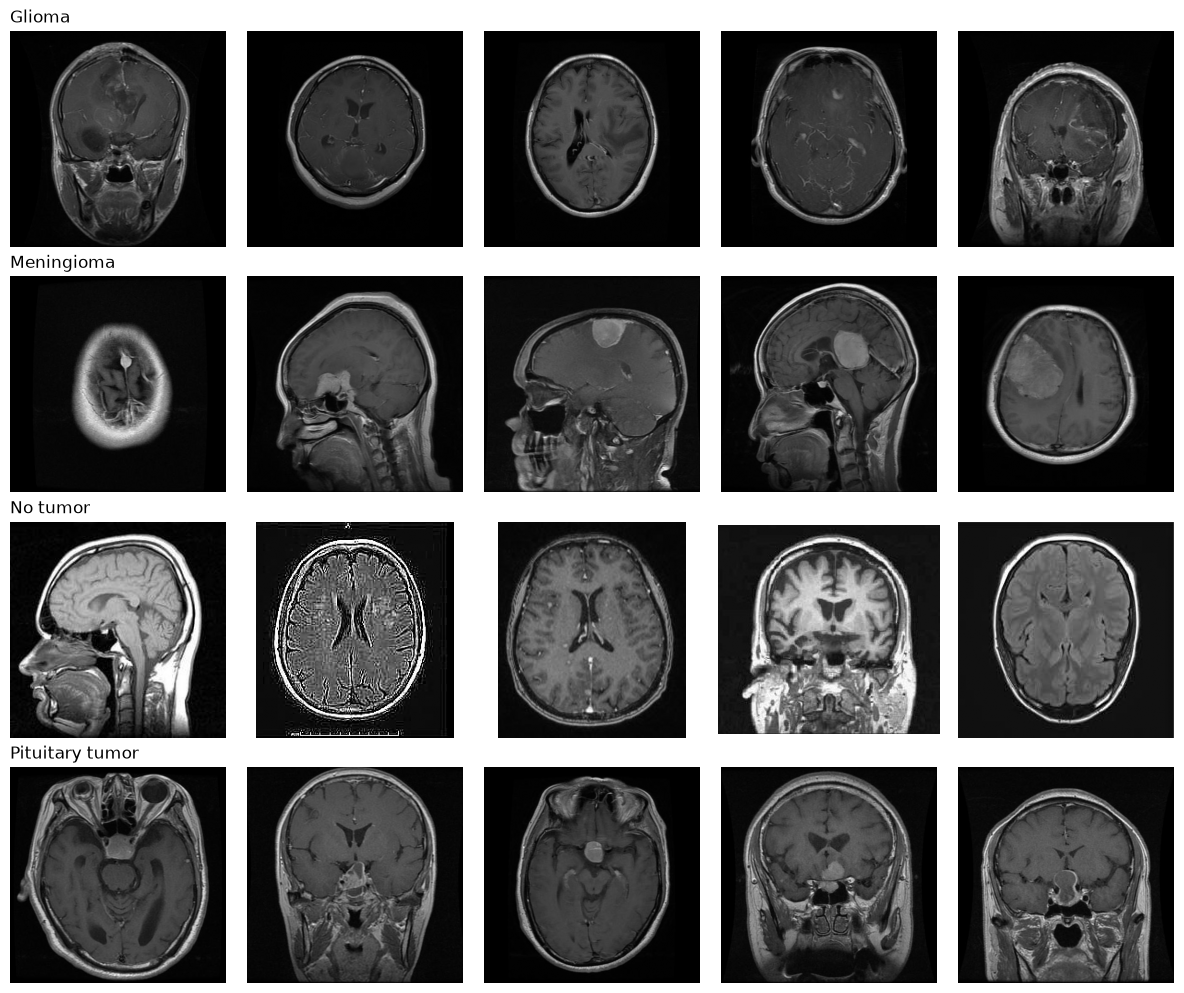

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
train = df[df.split == 'train']
for row, cls in zip(axes, train.cls.unique()):
    for ax, path in zip(row, train[train.cls == cls].sample(5, random_state=0).path):
        ax.imshow(Image.open(path).convert('L'), cmap='gray')
        ax.set_axis_off()
    row[0].set_title(cls, loc='left')
plt.tight_layout(); plt.show()

## Takeaways

- Balanced classes: no resampling or class weights needed.
- Mixed sizes and colour modes: normalise to greyscale, 224×224.
- Scans come in different planes (axial, coronal, sagittal) and framings: augment with crops, flips, small rotations and brightness/contrast changes.